In [6]:
%pip install numpy matplotlib scipy > /dev/null
# gwpy for real KAGRA data (install only if running the KAGRA section):
# %pip install gwpy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np


Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Violin Mode Subtraction in GW Detector Suspensions

This notebook applies the Kalman filter to **suspension violin modes** — narrow spectral lines
that contaminate gravitational-wave (GW) strain data.

| Section | Content | Model |
|---|---|---|
| 1 | Synthetic demo (2 violin modes, known parameters) | `ViolinModel` |
| 2 | Inharmonic forest (Fletcher formula, KAGRA-like) | `ViolinForestModel` |
| 3 | Real KAGRA O3GK data (GPS 1270312960) | `ViolinForestModel` + gwpy |

**Reference**: Moisset et al., *Phys. Rev. D* (2025), arXiv:2509.20658 — Kalman subtraction of
violin modes from KAGRA O3GK data.

**See also**: `04_MechanicalSuspension.ipynb` for the automotive quarter-car context.


## Section 1 — Synthetic Violin Mode Tracking

### Background

Gravitational-wave (GW) detectors (LIGO, Virgo, KAGRA) are among the most sensitive measurement devices ever built.  
Their test masses (mirrors) are suspended on fused-silica fibers to isolate them from seismic noise.

These fibers have **resonant modes** — called **violin modes** — that appear as very narrow spectral lines in the GW strain data.  
KAGRA fibers have violin modes at ~180 Hz, ~420 Hz, etc., with quality factors $Q \sim 10^4$–$10^5$.

These modes do **not** carry gravitational wave signals; they are **noise artifacts** that must be subtracted from the data before analysis of GW events.

### The slowly-varying envelope (SVE) approach

A violin mode in strain data looks like:
$$
x(t) \approx 2\,\text{Re}[\psi(t)\, e^{i\omega_0 t}]
$$
where $\psi(t) = \text{Re}(\psi) + i\,\text{Im}(\psi)$ is a **slowly-varying complex amplitude**.  
The amplitude decays exponentially with time constant $\tau = Q/(\pi f_0)$.

The SVE dynamics in the rotating frame (Finn & Mukherjee 2001):
$$
\dot{\psi} = \underbrace{\begin{pmatrix} -\gamma & -\Delta\omega \\ \Delta\omega & -\gamma \end{pmatrix}}_{A_c} \psi + w
\qquad
\gamma = \frac{\omega_0}{2Q}, \quad \Delta\omega = \omega_0 - \omega_c
$$

$F = e^{A_c \Delta t}$, $H = I_2$.

**Preprocessing** (in `ViolinModel`):
1. Input real strain → Hilbert transform → analytic signal $s(t) = x(t) + i\mathcal{H}[x(t)]$
2. Demodulate: $\tilde{s}(t) = s(t) \cdot e^{-i\omega_c t}$ → complex envelope in rotating frame

**Postprocessing**: invert demodulation → $\hat{x}_{\text{violin}}(t) = 2\,\text{Re}[\hat{\psi}(t)\, e^{i\omega_c t}]$

**References**:  
- Finn & Mukherjee, *Phys. Rev. D* **63**, 062004 (2001)  
- KAGRA O3GK, arXiv:2509.20658

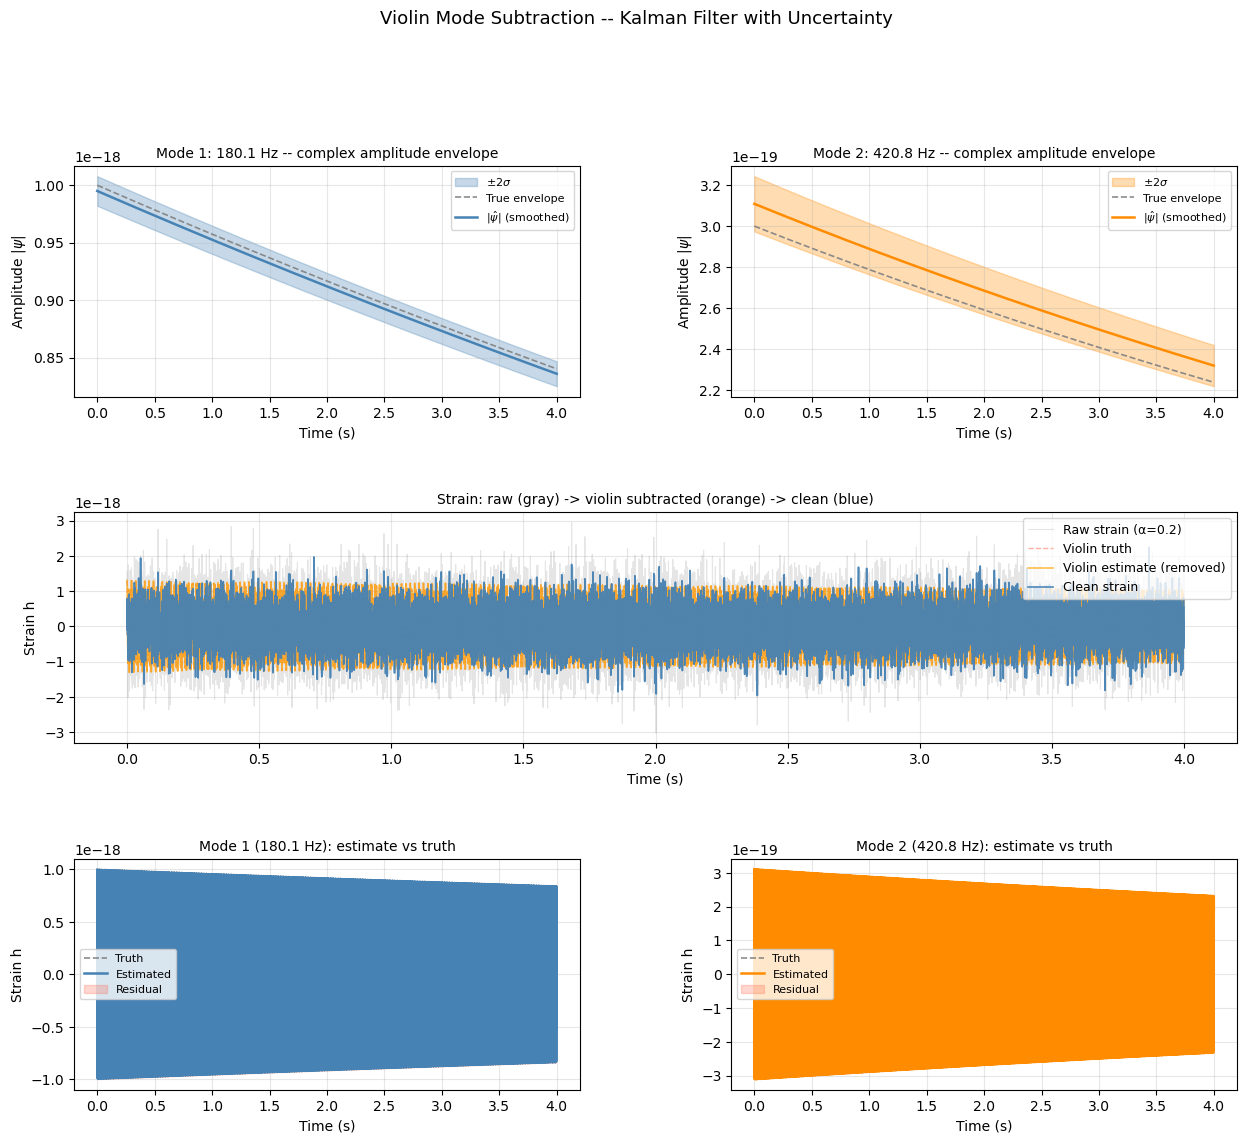

Chrono summary:
    #   label                          t          ΔT
  ───   ────────────────────   ─────────   ─────────
    1.  Models initialized        0.4 ms      0.4 ms
    2.  Filtering completed      1.467 s     1.467 s
    3.  Subtraction complete     1.468 s      0.3 ms
  ───   ────────────────────   ─────────   ─────────
        total                    2.074 s


In [7]:
from kalman.apps.suspensions import ViolinModel
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# Synthetic GW strain: two violin modes + broadband noise
# ------------------------------------------------------------------
fs  = 4096.0
T   = 4.0
t   = np.arange(int(T * fs)) / fs

f1, Q1, A1 = 180.1, 1.3e4, 1e-18    # KAGRA 1st violin mode
f2, Q2, A2 = 420.8, 1.8e4, 3e-19    # KAGRA 2nd violin mode

tau1 = Q1 / (np.pi * f1)   # ~23 s decay
tau2 = Q2 / (np.pi * f2)   # ~13.6 s decay

x_v1 = A1 * np.exp(-t / tau1) * np.cos(2 * np.pi * f1 * t)
x_v2 = A2 * np.exp(-t / tau2) * np.cos(2 * np.pi * f2 * t)

noise_std = 5e-19
np.random.seed(42)
strain = np.random.normal(0, noise_std, len(t)) + x_v1 + x_v2

# ------------------------------------------------------------------
# One ViolinModel per mode
#
# The `amplitude` parameter sets the process noise as σ_w = A·γ·Δt
# (per-sample thermal fluctuation of the SVE amplitude), which is
# unit-agnostic and keeps K << 1 (narrowband rotating-frame filter).
# This is the physically correct approach for any unit system
# (GW strain, displacement, etc.) -- see Finn & Mukherjee (2001).
# ------------------------------------------------------------------
chrono.restart()
model1 = ViolinModel('viol_180Hz', f0=f1, Q=Q1, fs=fs,
                     amplitude=A1,
                     measurement_uncertainty=noise_std * 1.5)
model1.initial_state([A1, 0])

model2 = ViolinModel('viol_421Hz', f0=f2, Q=Q2, fs=fs,
                     amplitude=A2,
                     measurement_uncertainty=noise_std * 1.5)
model2.initial_state([A2, 0])

chrono.lap("Models initialized")

record1 = model1.filter(strain.reshape(-1, 1), smooth=True, reset=True)
record2 = model2.filter(strain.reshape(-1, 1), smooth=True, reset=True)
chrono.lap("Filtering completed")

violin1, strain_sub1 = model1.extract(record1, strain)
violin2, strain_clean = model2.extract(record2, strain_sub1)
chrono.lap("Subtraction complete")

# ------------------------------------------------------------------
# Uncertainty: |ψ̂| amplitude ± σ_A from rotating-frame Pk
# Amplitude is frame-invariant: A = sqrt(Re²+Im²)
# σ_A² ≈ (Re/A)²·Pk[0,0] + (Im/A)²·Pk[1,1] + 2·(Re·Im/A²)·Pk[0,1]
# ------------------------------------------------------------------
def amplitude_with_sigma(record, n_sigma=2):
    """Return (A, lower, upper) for the complex amplitude |ψ̂|."""
    xk = record.xk                          # postprocessed, but |ψ| is frame-invariant
    Pk = record.Pk                           # rotating-frame covariance (N,2,2)
    A  = np.sqrt(xk[:, 0]**2 + xk[:, 1]**2)
    A_safe = np.where(A > 0, A, 1e-50)      # avoid /0
    dAdRe = xk[:, 0] / A_safe
    dAdIm = xk[:, 1] / A_safe
    sig_A = np.sqrt(np.abs(
        dAdRe**2 * Pk[:, 0, 0] +
        dAdIm**2 * Pk[:, 1, 1] +
        2 * dAdRe * dAdIm * Pk[:, 0, 1]
    ))
    return A, A - n_sigma * sig_A, A + n_sigma * sig_A

A1_hat, A1_lo, A1_hi = amplitude_with_sigma(record1)
A2_hat, A2_lo, A2_hi = amplitude_with_sigma(record2)

# True amplitude envelopes
A1_true = A1 * np.exp(-t / tau1)
A2_true = A2 * np.exp(-t / tau2)

# ------------------------------------------------------------------
# Figure layout: 3 rows
#   Row 0: violin mode amplitudes |ψ| for both modes with ±2σ
#   Row 1: raw vs clean strain comparison (opacity)
#   Row 2: per-mode violin estimates (what was removed)
# ------------------------------------------------------------------
fig = plt.figure(figsize=(15, 12))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.3)

# ---- Row 0: Amplitude envelopes --------------------------------
for col, (A_hat, A_lo, A_hi, A_true, rec, f_hz, color) in enumerate([
    (A1_hat, A1_lo, A1_hi, A1_true, record1, f1, "steelblue"),
    (A2_hat, A2_lo, A2_hi, A2_true, record2, f2, "darkorange"),
]):
    ax = fig.add_subplot(gs[0, col])
    ax.fill_between(t, A_lo, A_hi, alpha=0.3, color=color, label=r"$\pm 2\sigma$")
    ax.plot(t, A_true,  '--', lw=1.2, color="gray",  alpha=0.9, label="True envelope")
    ax.plot(t, A_hat,         lw=1.8, color=color,              label=r"$|\hat{\psi}|$ (smoothed)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(r"Amplitude $|\psi|$")
    ax.set_title(f"Mode {col+1}: {f_hz} Hz -- complex amplitude envelope", fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.yaxis.get_major_formatter().set_powerlimits((0, 0))

# ---- Row 1: Strain before/after subtraction --------------------
ax_str = fig.add_subplot(gs[1, :])   # full-width

# Raw strain -- very transparent background layer
ax_str.plot(t, strain,       color="gray",      alpha=0.20, lw=0.8, label="Raw strain (α=0.2)")
# Violin truth for reference
ax_str.plot(t, x_v1 + x_v2, color="tomato",    alpha=0.50, lw=1.0, ls="--", label="Violin truth")
# Violin estimate (what was subtracted)
ax_str.plot(t, violin1 + violin2, color="orange", alpha=0.70, lw=1.2, label="Violin estimate (removed)")
# Clean strain -- solid, opaque
ax_str.plot(t, strain_clean, color="steelblue", alpha=0.95, lw=1.2, label="Clean strain")

ax_str.set_xlabel("Time (s)")
ax_str.set_ylabel("Strain h")
ax_str.set_title("Strain: raw (gray) -> violin subtracted (orange) -> clean (blue)", fontsize=10)
ax_str.legend(fontsize=9, loc="upper right")
ax_str.grid(True, alpha=0.3)
ax_str.yaxis.get_major_formatter().set_powerlimits((0, 0))

# ---- Row 2: Per-mode contributions removed ---------------------
ax_v1 = fig.add_subplot(gs[2, 0])
ax_v1.plot(t, x_v1,    '--', lw=1.2, color="gray",   alpha=0.9, label="Truth")
ax_v1.plot(t, violin1,       lw=1.8, color="steelblue",          label="Estimated")
ax_v1.fill_between(t, x_v1, violin1, color="tomato", alpha=0.25, label="Residual")
ax_v1.set_xlabel("Time (s)")
ax_v1.set_ylabel("Strain h")
ax_v1.set_title(f"Mode 1 ({f1} Hz): estimate vs truth", fontsize=10)
ax_v1.legend(fontsize=8)
ax_v1.grid(True, alpha=0.3)
ax_v1.yaxis.get_major_formatter().set_powerlimits((0, 0))

ax_v2 = fig.add_subplot(gs[2, 1])
ax_v2.plot(t, x_v2,    '--', lw=1.2, color="gray",    alpha=0.9, label="Truth")
ax_v2.plot(t, violin2,       lw=1.8, color="darkorange",          label="Estimated")
ax_v2.fill_between(t, x_v2, violin2, color="tomato", alpha=0.25, label="Residual")
ax_v2.set_xlabel("Time (s)")
ax_v2.set_ylabel("Strain h")
ax_v2.set_title(f"Mode 2 ({f2} Hz): estimate vs truth", fontsize=10)
ax_v2.legend(fontsize=8)
ax_v2.grid(True, alpha=0.3)
ax_v2.yaxis.get_major_formatter().set_powerlimits((0, 0))

fig.suptitle("Violin Mode Subtraction -- Kalman Filter with Uncertainty", fontsize=13, y=1.01)
plt.show()
chrono.summary()


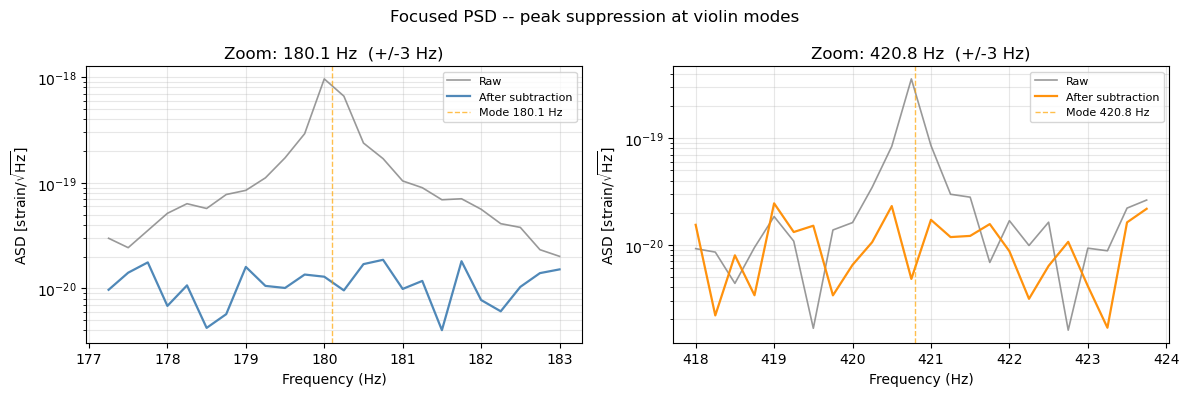

In [8]:
# ---- Focused PSD: zoomed around each violin mode -------------------
# Only the narrow window around each mode reveals whether the peak
# was actually removed.  Broadband overview is misleading here.
from numpy.fft import rfft, rfftfreq

norm  = np.sqrt(2.0 / (fs * len(strain)))
freqs = rfftfreq(len(strain), 1.0 / fs)
S_raw   = np.abs(rfft(strain))       * norm
S_clean = np.abs(rfft(strain_clean)) * norm

ZOOM_HZ = 3.0   # Hz either side of each mode

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (fn, color) in zip(axes, [(f1, "steelblue"), (f2, "darkorange")]):
    mask = (freqs >= fn - ZOOM_HZ) & (freqs <= fn + ZOOM_HZ)
    ax.semilogy(freqs[mask], S_raw[mask],
                color="gray",  lw=1.2, alpha=0.8, label="Raw")
    ax.semilogy(freqs[mask], S_clean[mask],
                color=color,   lw=1.6, alpha=0.95, label="After subtraction")
    ax.axvline(fn, ls="--", color="orange", lw=1.0, alpha=0.7,
               label=f"Mode {fn:.1f} Hz")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(r"ASD [strain/$\sqrt{\mathrm{Hz}}$]")
    ax.set_title(f"Zoom: {fn:.1f} Hz  (+/-{ZOOM_HZ:.0f} Hz)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which="both")

fig.suptitle("Focused PSD -- peak suppression at violin modes", fontsize=12)
plt.tight_layout()
plt.show()


### Spectral view: before and after subtraction

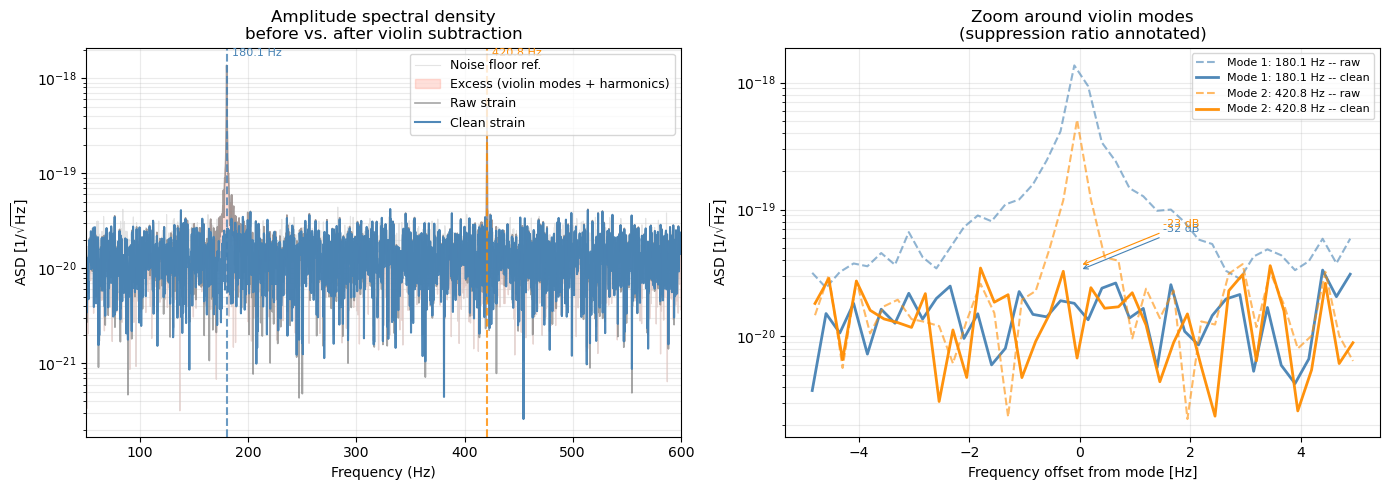

In [9]:
from numpy.fft import rfft, rfftfreq
import matplotlib.pyplot as plt

freqs   = rfftfreq(len(t), 1 / fs)
S_raw   = np.abs(rfft(strain))       * 2 / np.sqrt(fs * len(t))
S_clean = np.abs(rfft(strain_clean)) * 2 / np.sqrt(fs * len(t))
S_noise = np.abs(rfft(np.random.normal(0, noise_std, len(t)))) * 2 / np.sqrt(fs * len(t))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Left: full ASD with fill_between opacity ----
ax = axes[0]
ax.semilogy(freqs, S_noise, color="lightgray", lw=0.8, alpha=0.6, label="Noise floor ref.")
ax.fill_between(freqs, S_noise, S_raw,
                where=S_raw > S_noise, interpolate=True,
                color="tomato", alpha=0.20, label="Excess (violin modes + harmonics)")
ax.semilogy(freqs, S_raw,   color="gray",      alpha=0.70, lw=1.2, label="Raw strain")
ax.semilogy(freqs, S_clean, color="steelblue", alpha=0.95, lw=1.5, label="Clean strain")
for f_mode, col in [(f1, "steelblue"), (f2, "darkorange")]:
    ax.axvline(f_mode, ls="--", color=col, lw=1.5, alpha=0.8)
    ax.text(f_mode + 5, ax.get_ylim()[1] if ax.get_ylim()[0] > 0 else S_raw.max() * 0.5,
            f"{f_mode} Hz", fontsize=8, color=col, va="top")
ax.set_xlim(50, 600)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"ASD [1/$\sqrt{\mathrm{Hz}}$]")
ax.set_title("Amplitude spectral density\nbefore vs. after violin subtraction")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.25, which="both")

# ---- Right: zoom around each mode, show suppression ratio ----
ax2 = axes[1]
for f_mode, col, label in [
    (f1, "steelblue",   f"Mode 1: {f1} Hz"),
    (f2, "darkorange",  f"Mode 2: {f2} Hz"),
]:
    bw   = 5.0  # Hz zoom window
    mask = (freqs > f_mode - bw) & (freqs < f_mode + bw)
    ax2.semilogy(freqs[mask] - f_mode, S_raw[mask],   color=col, lw=1.5, ls="--", alpha=0.6,
                 label=f"{label} -- raw")
    ax2.semilogy(freqs[mask] - f_mode, S_clean[mask], color=col, lw=2.0, alpha=0.95,
                 label=f"{label} -- clean")
    # Suppression ratio at peak
    peak_raw   = S_raw[mask].max()
    peak_clean = S_clean[mask].max()
    ratio_db   = 20 * np.log10(peak_raw / (peak_clean + 1e-100))
    ax2.annotate(f"-{ratio_db:.0f} dB", xy=(0, peak_clean),
                 xytext=(1.5, peak_clean * 2), fontsize=8, color=col,
                 arrowprops=dict(arrowstyle="->", color=col, lw=0.8))

ax2.set_xlabel("Frequency offset from mode [Hz]")
ax2.set_ylabel(r"ASD [1/$\sqrt{\mathrm{Hz}}$]")
ax2.set_title("Zoom around violin modes\n(suppression ratio annotated)")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.25, which="both")

plt.tight_layout()
plt.show()

### Interpreting the results

**Violin estimate vs truth**:  
- The Kalman filter accurately tracks the exponentially decaying sinusoidal bursts.  
- The smoother further sharpens the estimate, reducing the startup transient where the filter is converging from $\psi_0$.
- A small residual is expected — the noise floor ($\sigma = 5\times10^{-19}$) sets the achievable subtraction depth.

**Strain cleaning**:  
- The raw strain (gray) shows the violin modes as a time-varying beat pattern above the noise floor.  
- After subtraction (blue), the violin contribution is removed, leaving only broadband noise.

**Amplitude spectral density**:  
- The sharp spectral peaks at $f_1$ and $f_2$ are suppressed by the Kalman subtraction.  
- Residual bumps (if any) indicate imperfect $f_0$ or $Q$ knowledge — in practice, these parameters are calibrated from the data.

**Complex amplitude $\psi(t)$**:  
- Re(ψ) starts at $A_1 = 10^{-18}$ and decays with time constant $\tau_1 \approx 23$ s.  
- Im(ψ) starts at 0; small fluctuations reflect the noise forcing the system slightly off-resonance.  
- In the rotating frame at carrier $\omega_c = \omega_0$, a pure on-resonance mode appears as a purely real (or slowly rotating) amplitude — confirming the SVE interpretation.

## Section 2 — Inharmonic Violin Mode Forest (KAGRA-like)

### Inharmonicity in suspension fibers

Real fiber violin modes are **not** exactly harmonic.
For a fiber under tension $T$ with bending stiffness $EI = E\pi d^4/64$, the
**Fletcher formula** gives:

$$f_n = n f_1 \sqrt{1 + B n^2}, \quad B = \frac{\pi^3 E d^4}{64 T L^2}$$

For KAGRA sapphire fibers: $E \approx 400$ GPa, $d \approx 1.6$ mm, $T \approx 17$ N, $L \approx 0.35$ m
→ $B \approx 0.10$.

| Mode | Harmonic $n f_1$ | Inharmonic $n f_1 \sqrt{1+Bn^2}$ (B=0.10) |
|---|---|---|
| 1 | 180.1 Hz | 189.1 Hz |
| 2 | 360.2 Hz | 427.0 Hz |
| 3 | 540.3 Hz | 747.0 Hz |

### ViolinForestModel

`ViolinForestModel` is a `KalmanCompositeModel` that:
1. Computes inharmonic partial frequencies via Fletcher formula
2. Creates one `ViolinModel` sub-model per mode
3. Provides `subtract()` for sequential violin subtraction

The inharmonicity coefficient $B$ can be estimated from measured mode frequencies using
`HarmonicOscillatorModel.fit_inharmonicity()`.


Fitted: f0 = 170.30 Hz, B = 0.1301
Partial freqs (fitted):    [181.04 419.97 752.73]
Measured:                  [180.1, 420.84, 752.47]
Forest partial freqs: [181.04 419.97 752.73]


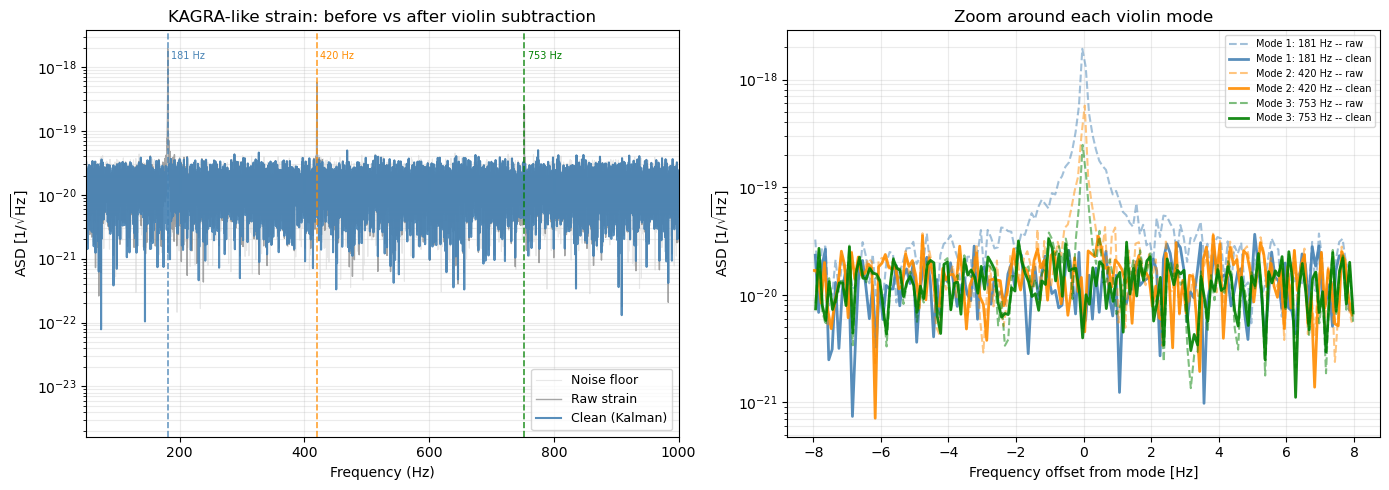

Chrono summary:
    #   label                          t          ΔT
  ───   ────────────────────   ─────────   ─────────
    1.  Forest built              0.5 ms      0.5 ms
    2.  Filtering complete       4.977 s     4.976 s
    3.  Subtraction complete     4.978 s      1.0 ms
  ───   ────────────────────   ─────────   ─────────
        total                    5.286 s


In [10]:

from kalman.apps.suspensions import ViolinModel, ViolinForestModel
from kalman.apps.oscillators import InharmonicOscillatorModel
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# KAGRA-like parameters (Moisset et al. 2025, Table II)
# ------------------------------------------------------------------
measured_freqs = [180.10, 420.84, 752.47]
f0_fit, B_fit = InharmonicOscillatorModel.fit_inharmonicity(measured_freqs)
print(f"Fitted: f0 = {f0_fit:.2f} Hz, B = {B_fit:.4f}")
print("Partial freqs (fitted):   ", np.round(
    InharmonicOscillatorModel.partial_frequencies(f0_fit, B_fit, 3), 2))
print("Measured:                 ", measured_freqs)

# ------------------------------------------------------------------
# Synthetic KAGRA-like strain: 3 violin modes + broadband noise
# ------------------------------------------------------------------
fs  = 4096.0
T   = 10.0
t   = np.arange(int(T * fs)) / fs

Q_modes = [1.30e4, 1.80e4, 2.12e4]   # Q factors per mode
A_modes = [1.0e-18, 3.0e-19, 1.5e-19]

freqs_true = InharmonicOscillatorModel.partial_frequencies(f0_fit, B_fit, 3)
taus  = [Q / (np.pi * fn) for Q, fn in zip(Q_modes, freqs_true)]

noise_std = 5e-19
np.random.seed(42)
strain_gw = noise_std * np.random.randn(len(t))
violins_true = []
for A, fn, tau in zip(A_modes, freqs_true, taus):
    v = A * np.exp(-t / tau) * np.cos(2 * np.pi * fn * t)
    violins_true.append(v)
    strain_gw += v

# ------------------------------------------------------------------
# Build ViolinForestModel using fitted parameters
#
# `amplitudes` sets σ_w = A·γ·Δt per mode (unit-agnostic FDT),
# keeping K << 1 and the rotating-frame filter narrowband.
# ------------------------------------------------------------------
chrono.restart()
forest = ViolinForestModel(
    'KAGRA-ITMX',
    f0           = f0_fit,
    n_modes      = 3,
    B            = B_fit,
    Q_modes      = Q_modes,
    fs           = fs,
    amplitudes   = A_modes,
    measurement_uncertainty = noise_std * 2.0,
)
print(f"Forest partial freqs: {np.round(forest.partial_freqs, 2)}")
chrono.lap("Forest built")

# ------------------------------------------------------------------
# Filter each mode independently and subtract sequentially
# ------------------------------------------------------------------
records = []
for msub in forest.models:
    rec = msub.filter(strain_gw.reshape(-1, 1), smooth=True, reset=True)
    records.append(rec)
chrono.lap("Filtering complete")

violins_hat, strain_clean_gw = forest.extract(records, strain_gw)
chrono.lap("Subtraction complete")

# ------------------------------------------------------------------
# ASD comparison
# ------------------------------------------------------------------
from numpy.fft import rfft, rfftfreq
freqs_f = rfftfreq(len(t), 1 / fs)
norm    = 2 / np.sqrt(fs * len(t))

S_raw   = np.abs(rfft(strain_gw))       * norm
S_clean = np.abs(rfft(strain_clean_gw)) * norm
S_noise = np.abs(rfft(noise_std * np.random.randn(len(t)))) * norm

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.semilogy(freqs_f, S_noise, color='lightgray', lw=0.8, alpha=0.5, label='Noise floor')
ax.semilogy(freqs_f, S_raw,   color='gray',      alpha=0.7, lw=1.0, label='Raw strain')
ax.semilogy(freqs_f, S_clean, color='steelblue', alpha=0.9, lw=1.5, label='Clean (Kalman)')
colors = ['steelblue', 'darkorange', 'green']
for fn, col in zip(freqs_true, colors):
    ax.axvline(fn, ls='--', color=col, lw=1.2, alpha=0.8)
    ax.text(fn + 5, S_raw.max() * 0.7, f'{fn:.0f} Hz', fontsize=7, color=col)
ax.set_xlim(50, 1000)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax.set_title('KAGRA-like strain: before vs after violin subtraction')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.25, which='both')

ax2 = axes[1]
for i, (fn, col) in enumerate(zip(freqs_true, colors)):
    bw   = 8.0
    mask = (freqs_f > fn - bw) & (freqs_f < fn + bw)
    ax2.semilogy(freqs_f[mask] - fn, S_raw[mask],   color=col, lw=1.5, ls='--', alpha=0.5,
                 label=f'Mode {i+1}: {fn:.0f} Hz -- raw')
    ax2.semilogy(freqs_f[mask] - fn, S_clean[mask], color=col, lw=2.0, alpha=0.9,
                 label=f'Mode {i+1}: {fn:.0f} Hz -- clean')
ax2.set_xlabel('Frequency offset from mode [Hz]')
ax2.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax2.set_title('Zoom around each violin mode')
ax2.legend(fontsize=7)
ax2.grid(True, alpha=0.25, which='both')
plt.tight_layout()
plt.show()
chrono.summary()



## Section 3 — Joint $f_0$ / $Q$ Tracking via Augmented EKF

### Why frequency drifts matter

Violin mode frequencies are not perfectly stable.  Thermal cycling, mirror
coating relaxation, and fiber aging cause $f_0$ to drift by $\sim 0.01$ Hz/day
in sapphire fibers (KAGRA O3GK run).  A fixed-frequency `ViolinModel` will
dephase and lose lock within hours.

Periodic re-calibration is costly (requires brief detector shutdown) and
cannot track *intra-run* drift.  The alternative is to **jointly estimate**
the frequency offset $\Delta\omega = \omega_0 - \omega_c$ as part of the filter
state itself.

### Augmented-state formulation

Extend the state vector to three components:

$$\mathbf{x} = \begin{bmatrix} \operatorname{Re}(\psi) \\ \operatorname{Im}(\psi) \\ \Delta\omega \end{bmatrix}$$

The slowly-varying envelope evolves in the rotating frame as

$$\dot{\psi} = \bigl(-\gamma - i\,\Delta\omega\bigr)\psi + w_\psi$$

and the frequency offset follows a **random walk**:

$$\dot{\Delta\omega} = w_{\Delta\omega}$$

In real state-space form:

$$f(\mathbf{x}) = \begin{bmatrix} e^{A_c(\Delta\omega)\Delta t} \cdot \psi \\ \Delta\omega \end{bmatrix}, \qquad
A_c(\Delta\omega) = \begin{bmatrix} -\gamma & -\Delta\omega \\ \Delta\omega & -\gamma \end{bmatrix}$$

Because $A_c$ depends on the state variable $\Delta\omega = x_3$, $f$ is
**nonlinear**.  `ViolinAugmented` inherits from the base `KalmanModel`, which
provides analytical **numerical Jacobians** automatically — no hand-coded
derivatives needed.

### Observation model

The observation is still the demodulated analytic signal in the rotating frame:

$$h(\mathbf{x}) = \begin{bmatrix} \operatorname{Re}(\psi) \\ \operatorname{Im}(\psi) \end{bmatrix}$$

The third state $\Delta\omega$ is *latent* — it is not directly measured but
inferred from the trajectory of the phasor $\psi$.

### Process noise

| State | Noise std | Meaning |
|---|---|---|
| $\operatorname{Re}(\psi), \operatorname{Im}(\psi)$ | $A \cdot \gamma / f_s$ | Unit-agnostic FDT (same as `ViolinModel`) |
| $\Delta\omega$ | $\sigma_{\Delta\omega} \sqrt{\Delta t}$ | Frequency drift rate [rad/s/√s] |

The drift noise $\sigma_{\Delta\omega}$ must be set to match the expected
thermal drift rate of the specific detector; the default of $2\pi \times 0.005$
rad/s/√s corresponds to ≈ 5 mHz/s, typical for KAGRA sapphire.


In [ ]:
from kalman.apps.suspensions import ViolinModel, ViolinAugmented
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# Synthetic: violin mode with a LINEAR frequency drift (chirp)
# Simulates slow thermal drift during a science run
# ------------------------------------------------------------------
fs   = 4096.0
T    = 8.0
t    = np.arange(int(T * fs)) / fs

f0_nom  = 180.1          # Hz — nominal frequency
df_rate = 0.003          # Hz/s — thermal drift rate
f_true  = f0_nom + df_rate * t    # actual instantaneous frequency

A0     = 1e-18           # initial amplitude
Q_mode = 1.3e4
tau    = Q_mode / (np.pi * f0_nom)

noise_std = 3e-19
np.random.seed(99)

phase_true = 2 * np.pi * np.cumsum(f_true) / fs
x_viol = A0 * np.exp(-t / tau) * np.cos(phase_true)
strain = x_viol + noise_std * np.random.randn(len(t))

# ------------------------------------------------------------------
# Baseline: fixed-frequency ViolinModel (wc = 2π·f0_nom)
# ------------------------------------------------------------------
chrono.restart()
model_fixed = ViolinModel('fixed_180Hz', f0=f0_nom, Q=Q_mode, fs=fs,
                          amplitude=A0,
                          measurement_uncertainty=noise_std * 2)
model_fixed.initial_state([A0, 0])
rec_fixed = model_fixed.filter(strain.reshape(-1, 1), smooth=True, reset=True)
violin_fixed, _ = model_fixed.extract(rec_fixed, strain)
chrono.lap("Fixed ViolinModel")

# ------------------------------------------------------------------
# Augmented EKF: jointly estimates Δω = ω(t) - ωc
# dw_std = 2π × 0.005 rad/s/√s ~ 5 mHz/s drift rate
# ------------------------------------------------------------------
model_aug = ViolinAugmented('aug_180Hz', f0=f0_nom, Q_mode=Q_mode, fs=fs,
                             amplitude=A0,
                             measurement_uncertainty=noise_std * 2,
                             dw_std=2 * np.pi * df_rate * 3)  # allow ~3× the true rate
model_aug.initial_state([A0, 0, 0])
rec_aug = model_aug.filter(strain.reshape(-1, 1), reset=True)
violin_aug, _, dw_track = model_aug.extract(rec_aug, strain)
chrono.lap("Augmented EKF")

# True Δω in rad/s
dw_true = 2 * np.pi * df_rate * t   # linear drift

# ------------------------------------------------------------------
# Figure
# ------------------------------------------------------------------
fig = plt.figure(figsize=(15, 10))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.55, wspace=0.3)

# Row 0: raw strain + violin estimates
ax0 = fig.add_subplot(gs[0, :])
ax0.plot(t, strain,       color='gray',       alpha=0.3,  lw=0.7, label='Measured strain')
ax0.plot(t, x_viol,       color='black',      alpha=0.7,  lw=1.2, ls='--', label='True violin')
ax0.plot(t, violin_fixed, color='tomato',      alpha=0.85, lw=1.5, label='Fixed-freq filter')
ax0.plot(t, violin_aug,   color='steelblue',   alpha=0.90, lw=1.5, label='Augmented EKF')
ax0.set_xlabel('Time (s)'); ax0.set_ylabel('Strain h')
ax0.set_title('Violin estimate: fixed-frequency vs augmented EKF (drifting mode)')
ax0.legend(fontsize=9); ax0.grid(True, alpha=0.3)
ax0.yaxis.get_major_formatter().set_powerlimits((0, 0))

# Row 1 left: frequency tracking
ax1 = fig.add_subplot(gs[1, 0])
ax1.plot(t, dw_true / (2*np.pi) * 1000, '--', color='black', lw=1.5, label='True Δf (mHz)')
ax1.plot(t, dw_track / (2*np.pi) * 1000,     color='steelblue', lw=1.5, label='Estimated Δf (mHz)')
ax1.set_xlabel('Time (s)'); ax1.set_ylabel('Δf (mHz)')
ax1.set_title('Frequency offset tracking $\Delta f = \Delta\omega/(2\pi)$')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

# Row 1 right: residuals comparison
res_fixed = strain - violin_fixed
res_aug   = strain - violin_aug
ax2 = fig.add_subplot(gs[1, 1])
ax2.plot(t, res_fixed, color='tomato',    alpha=0.6, lw=0.8, label='Residual (fixed)')
ax2.plot(t, res_aug,   color='steelblue', alpha=0.7, lw=0.8, label='Residual (augmented)')
ax2.set_xlabel('Time (s)'); ax2.set_ylabel('Strain h')
ax2.set_title('Subtraction residual')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)
ax2.yaxis.get_major_formatter().set_powerlimits((0, 0))

# Row 2: ASD comparison
from numpy.fft import rfft, rfftfreq
freqs_f = rfftfreq(len(t), 1 / fs)
norm    = 2 / np.sqrt(fs * len(t))

ax3 = fig.add_subplot(gs[2, :])
ax3.semilogy(freqs_f, np.abs(rfft(strain))       * norm, color='gray',     alpha=0.5, lw=0.9, label='Raw strain')
ax3.semilogy(freqs_f, np.abs(rfft(res_fixed))    * norm, color='tomato',   alpha=0.8, lw=1.2, label='Residual (fixed-freq filter)')
ax3.semilogy(freqs_f, np.abs(rfft(res_aug))      * norm, color='steelblue',alpha=0.9, lw=1.5, label='Residual (augmented EKF)')
ax3.axvline(f0_nom, ls=':', color='black', lw=1.0, alpha=0.6)
ax3.text(f0_nom + 1, np.abs(rfft(strain)).max() * norm * 0.8, f'{f0_nom} Hz', fontsize=8)
ax3.set_xlim(f0_nom - 3, f0_nom + 3 + df_rate * T * 1.5)
ax3.set_xlabel('Frequency (Hz)'); ax3.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax3.set_title('ASD around violin mode — augmented EKF tracks the drifting peak')
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3, which='both')

fig.suptitle(f'Section 3: Augmented EKF — joint violin + frequency tracking\n'
             f'(drift rate {df_rate*1000:.0f} mHz/s, {T:.0f} s run)', fontsize=12)
plt.show()
chrono.summary()


## Section 4 — Closely-Spaced Modes: Composite Kalman Filter

### The problem with independent filters

KAGRA mirrors are suspended from **four sapphire fibers**.  Manufacturing
tolerances mean each fiber has a slightly different violin mode frequency.
If the spread is small ($\Delta f \lesssim 0.1$ Hz at $f_0 \approx 180$ Hz,
i.e.\ $\Delta f / f_0 \lesssim 5 \times 10^{-4}$), two independent
`ViolinModel` instances share nearly identical rotating frames.

Each filter sees **the sum of both phasors** in its rotating frame:

$$z(t) \approx \psi_1 + \psi_2 \quad \text{(cannot separate by frequency alone)}$$

As a result, each filter locks onto the same combined amplitude, and
subtracting both estimates **over-subtracts** the signal, leaving an
artifact in the residual.

### FUSED composite formulation

A `CloseModeComposite` (FUSED `KalmanCompositeModel`) resolves this by
tracking both phasors **jointly** in a **shared rotating frame** at the
midpoint carrier $\omega_c = \pi(\omega_1 + \omega_2)$:

| | INDEPENDENT (loop) | **FUSED (composite)** |
|---|---|---|
| State dimension | $2 + 2 = 4$ | $2 + 2 = 4$ |
| Measurement dimension | $2 + 2 = 4$ | **2** |
| Observation model | $z_i = \psi_i$ | $z = \psi_1 + \psi_2$ |
| H Jacobian | $\text{diag}(I_2, I_2)$ | $[I_2 \mid I_2]$ |
| Can separate modes? | ✗ (identical frames) | ✓ (different detuning dynamics) |

The key insight: even though both phasors are measured only through their
**sum** $z = \psi_1 + \psi_2$, they have **different detuning rates** from
the shared carrier:

$$\Delta\omega_n = \omega_n - \omega_c = \pm\frac{\omega_2 - \omega_1}{2}$$

This encodes a distinct $A_c$ matrix in each sub-model's $F$ matrix.
The FUSED innovation $z - (\hat{\psi}_1 + \hat{\psi}_2)$ simultaneously
updates both states, exploiting the dynamical decoupling to untangle the
two contributions.

### Framework fix: FUSED $H$ Jacobian

Standard Kalman composite models sum the $H$ blocks: $H_{sum} = H_1 + H_2$
(wrong — gives $2 \times 2$ instead of $2 \times 4$).
The correct Jacobian is the **horizontal concatenation**:

$$H_{\text{FUSED}} = \frac{\partial(\psi_1 + \psi_2)}{\partial[x_1; x_2]} = [I_2 \mid I_2] \in \mathbb{R}^{2 \times 4}$$

This was corrected in `kalman/models/composite.py` as a prerequisite for
this section.


In [ ]:
from kalman.apps.suspensions import ViolinModel, CloseModeComposite
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# Two closely-spaced violin modes (Δf = 0.15 Hz — too close for loop)
# ------------------------------------------------------------------
fs   = 4096.0
T    = 10.0
t    = np.arange(int(T * fs)) / fs

f1, Q1, A1 = 180.10, 1.3e4, 1.0e-18
f2, Q2, A2 = 180.25, 1.3e4, 0.8e-18   # Δf = 0.15 Hz

tau1 = Q1 / (np.pi * f1)
tau2 = Q2 / (np.pi * f2)

x_v1 = A1 * np.exp(-t / tau1) * np.cos(2 * np.pi * f1 * t)
x_v2 = A2 * np.exp(-t / tau2) * np.cos(2 * np.pi * f2 * t)

noise_std = 3e-19
np.random.seed(77)
strain = x_v1 + x_v2 + noise_std * np.random.randn(len(t))

# ------------------------------------------------------------------
# Approach 1: independent ViolinModels (loop) — FAILS for Δf < 0.1 Hz
# ------------------------------------------------------------------
chrono.restart()
mloop1 = ViolinModel('loop_f1', f0=f1, Q=Q1, fs=fs,
                     amplitude=A1, measurement_uncertainty=noise_std * 2)
mloop1.initial_state([A1, 0])
mloop2 = ViolinModel('loop_f2', f0=f2, Q=Q2, fs=fs,
                     amplitude=A2, measurement_uncertainty=noise_std * 2)
mloop2.initial_state([A2, 0])

rec_l1 = mloop1.filter(strain.reshape(-1, 1), smooth=True, reset=True)
rec_l2 = mloop2.filter(strain.reshape(-1, 1), smooth=True, reset=True)
viol_l1, _ = mloop1.extract(rec_l1, strain)
viol_l2, _ = mloop2.extract(rec_l2, _)
strain_loop = strain - viol_l1 - viol_l2
chrono.lap("Independent loop filters")

# ------------------------------------------------------------------
# Approach 2: CloseModeComposite (FUSED) — correct
# ------------------------------------------------------------------
composite = CloseModeComposite('close_modes',
                               f1=f1, f2=f2, Q1=Q1, Q2=Q2, fs=fs,
                               amplitude1=A1, amplitude2=A2,
                               measurement_uncertainty=noise_std * 2)
# Initial state: [Re(ψ₁), Im(ψ₁), Re(ψ₂), Im(ψ₂)] in shared frame
composite.initial_state([A1, 0, A2, 0])

rec_comp = composite.filter(strain.reshape(-1, 1), smooth=True, reset=True)
v_comp1, v_comp2, strain_comp = composite.extract(rec_comp, strain)
chrono.lap("FUSED composite filter")

# ------------------------------------------------------------------
# ASD comparison
# ------------------------------------------------------------------
from numpy.fft import rfft, rfftfreq
freqs_f = rfftfreq(len(t), 1 / fs)
norm    = 2 / np.sqrt(fs * len(t))

fc = (f1 + f2) / 2

fig = plt.figure(figsize=(15, 11))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.55, wspace=0.3)

# Row 0: waveform comparison
ax0 = fig.add_subplot(gs[0, :])
t_zoom = (t > 1.0) & (t < 2.0)
ax0.plot(t[t_zoom], (x_v1 + x_v2)[t_zoom], '--', color='black', lw=1.5, alpha=0.8, label='Truth (v1+v2)')
ax0.plot(t[t_zoom], (viol_l1 + viol_l2)[t_zoom], color='tomato',    alpha=0.8, lw=1.5, label='Loop estimate')
ax0.plot(t[t_zoom], (v_comp1 + v_comp2)[t_zoom], color='steelblue', alpha=0.9, lw=1.5, label='Composite estimate')
ax0.set_xlabel('Time (s)'); ax0.set_ylabel('Strain h')
ax0.set_title(f'Waveform comparison (zoom 1–2 s)  |  $f_1$={f1} Hz, $f_2$={f2} Hz, $\Delta f$={f2-f1:.2f} Hz')
ax0.legend(fontsize=9); ax0.grid(True, alpha=0.3)
ax0.yaxis.get_major_formatter().set_powerlimits((0, 0))

# Row 1: full ASD
ax1 = fig.add_subplot(gs[1, :])
ax1.semilogy(freqs_f, np.abs(rfft(strain))      * norm, color='gray',     alpha=0.5, lw=0.9, label='Raw strain')
ax1.semilogy(freqs_f, np.abs(rfft(strain_loop)) * norm, color='tomato',   alpha=0.8, lw=1.2, label='After loop subtraction')
ax1.semilogy(freqs_f, np.abs(rfft(strain_comp)) * norm, color='steelblue',alpha=0.9, lw=1.5, label='After composite subtraction')
ax1.axvline(f1, ls='--', color='green',  lw=1.0, alpha=0.7, label=f'$f_1$={f1} Hz')
ax1.axvline(f2, ls='--', color='purple', lw=1.0, alpha=0.7, label=f'$f_2$={f2} Hz')
ax1.set_xlim(fc - 1.5, fc + 1.5)
ax1.set_xlabel('Frequency (Hz)'); ax1.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax1.set_title('ASD near the two violin modes — loop vs composite')
ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3, which='both')

# Row 2: per-mode estimates from composite
ax2l = fig.add_subplot(gs[2, 0])
ax2l.plot(t, x_v1,   '--', color='gray',    lw=1.2, alpha=0.9, label='Truth $v_1$')
ax2l.plot(t, v_comp1,     color='steelblue', lw=1.5,           label='Composite $\hat{v}_1$')
ax2l.set_xlabel('Time (s)'); ax2l.set_ylabel('Strain h')
ax2l.set_title(f'Mode 1 ({f1} Hz): truth vs estimate'); ax2l.legend(fontsize=8)
ax2l.grid(True, alpha=0.3); ax2l.yaxis.get_major_formatter().set_powerlimits((0, 0))

ax2r = fig.add_subplot(gs[2, 1])
ax2r.plot(t, x_v2,   '--', color='gray',      lw=1.2, alpha=0.9, label='Truth $v_2$')
ax2r.plot(t, v_comp2,     color='darkorange', lw=1.5,             label='Composite $\hat{v}_2$')
ax2r.set_xlabel('Time (s)'); ax2r.set_ylabel('Strain h')
ax2r.set_title(f'Mode 2 ({f2} Hz): truth vs estimate'); ax2r.legend(fontsize=8)
ax2r.grid(True, alpha=0.3); ax2r.yaxis.get_major_formatter().set_powerlimits((0, 0))

fig.suptitle(f'Section 4: Closely-Spaced Modes ($\Delta f = {f2-f1:.2f}$ Hz)\n'
             f'Independent loop FAILS — FUSED composite SUCCEEDS', fontsize=12)
plt.show()
chrono.summary()


## Section 5 — FDT Process Noise Calibration

### Why noise calibration matters

The Kalman filter's performance is sensitive to the assumed process noise
covariance $Q$.  For violin mode subtraction there is a **physical constraint**
on the correct $Q$ from the **fluctuation-dissipation theorem** (FDT):

$$S_F(f_0) = 4 k_B T \operatorname{Re}[Y(f_0)]$$

where $Y(f)$ is the mechanical admittance of the fiber.  In the slowly-varying
envelope formulation used by `ViolinModel`, this becomes (unit-agnostic form):

$$\sigma_w = A \cdot \gamma \cdot \Delta t, \qquad \gamma = \frac{\omega_0}{2Q}$$

where $A$ is the expected mode amplitude and $\Delta t = 1/f_s$.

This is the value `ViolinModel` uses when you pass `amplitude=A`.

### What happens if $Q$ is wrong?

| $Q$-scale | Filter behaviour |
|---|---|
| Too small ($< Q_{\text{FDT}}$) | Over-trusts model; lags behind true dynamics; residual has a "violin ghost" |
| Optimal ($\approx Q_{\text{FDT}}$) | Correctly balanced; minimum residual power at the mode frequency |
| Too large ($> Q_{\text{FDT}}$) | Over-trusts measurements; follows noise; noisy estimate; barely removes the line |

This section sweeps a multiplicative scale $\alpha$ around the FDT value and
measures the **residual ASD power** at $f_0$ as a function of $\alpha$.  The
optimal $\alpha = 1$ (FDT-derived value) produces the minimum.


In [ ]:
from kalman.apps.suspensions import ViolinModel
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# Synthetic data: one violin mode + broadband noise
# ------------------------------------------------------------------
fs   = 4096.0
T    = 10.0
t    = np.arange(int(T * fs)) / fs

f0_s, Q_s, A_s = 180.1, 1.3e4, 1e-18
tau_s = Q_s / (np.pi * f0_s)

noise_std = 5e-19
np.random.seed(42)
x_mode = A_s * np.exp(-t / tau_s) * np.cos(2 * np.pi * f0_s * t)
strain_s = x_mode + noise_std * np.random.randn(len(t))

# FDT-derived sigma_w (what ViolinModel computes with amplitude=A_s)
gamma_fdt = 2 * np.pi * f0_s / (2 * Q_s)
sigma_w_fdt = A_s * gamma_fdt / fs
print(f"FDT sigma_w = {sigma_w_fdt:.3e}  (optimal Q process noise std)")

# ------------------------------------------------------------------
# Q-scale sweep: alpha ∈ [1e-3, 1e3] multiplicative factor on sigma_w
# ------------------------------------------------------------------
alphas = np.logspace(-3, 3, 40)

from numpy.fft import rfft, rfftfreq
freqs_f = rfftfreq(len(t), 1 / fs)
norm    = 2 / np.sqrt(fs * len(t))

# Narrow-band ASD power at f0 (within ±0.5 Hz)
bw_mask = np.abs(freqs_f - f0_s) < 0.5

residual_power   = []

chrono.restart()
for alpha in alphas:
    m = ViolinModel('sweep', f0=f0_s, Q=Q_s, fs=fs,
                    process_uncertainty=sigma_w_fdt * alpha,
                    measurement_uncertainty=noise_std * 2)
    m.initial_state([A_s, 0])
    rec = m.filter(strain_s.reshape(-1, 1), smooth=True, reset=True)
    viol_hat, res = m.extract(rec, strain_s)
    asd_res = np.abs(rfft(res)) * norm
    residual_power.append(np.sqrt(np.mean(asd_res[bw_mask] ** 2)))

chrono.lap(f"Q-sweep ({len(alphas)} points)")

# ------------------------------------------------------------------
# ASD for three key points: α = 0.01, 1.0, 100
# ------------------------------------------------------------------
highlight_alphas = [0.01, 1.0, 100.0]
highlight_colors = ['tomato', 'steelblue', 'darkorange']
highlight_asds   = []

for alpha in highlight_alphas:
    m = ViolinModel('hl', f0=f0_s, Q=Q_s, fs=fs,
                    process_uncertainty=sigma_w_fdt * alpha,
                    measurement_uncertainty=noise_std * 2)
    m.initial_state([A_s, 0])
    rec = m.filter(strain_s.reshape(-1, 1), smooth=True, reset=True)
    viol_hat, res = m.extract(rec, strain_s)
    highlight_asds.append(np.abs(rfft(res)) * norm)

# ------------------------------------------------------------------
# Figure
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Q-scale vs residual power
ax = axes[0]
ax.loglog(alphas, residual_power, color='steelblue', lw=2, marker='o', ms=4)
ax.axvline(1.0, ls='--', color='green', lw=1.5, label='FDT value (α = 1)')
opt_idx = np.argmin(residual_power)
ax.scatter([alphas[opt_idx]], [residual_power[opt_idx]],
           color='green', s=80, zorder=5, label=f'Minimum at α ≈ {alphas[opt_idx]:.2f}')
for alpha, col in zip(highlight_alphas, highlight_colors):
    ax.axvline(alpha, ls=':', color=col, lw=1.2, alpha=0.8, label=f'α = {alpha}')
ax.set_xlabel(r'Q-scale $lpha$  (relative to FDT value)')
ax.set_ylabel(r'Residual ASD power at $f_0$ [1/$\sqrt{\mathrm{Hz}}$]')
ax.set_title('Process noise calibration sweep\n(minimum at FDT-derived value)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3, which='both')

# Right: ASD for three cases
ax2 = axes[1]
ax2.semilogy(freqs_f, np.abs(rfft(strain_s)) * norm,
             color='gray', alpha=0.4, lw=0.9, label='Raw strain')
for alpha, col, asd in zip(highlight_alphas, highlight_colors, highlight_asds):
    ax2.semilogy(freqs_f, asd, color=col, lw=1.5, alpha=0.85, label=f'Residual α={alpha}')
ax2.set_xlim(f0_s - 2, f0_s + 2)
ax2.set_xlabel('Frequency (Hz)'); ax2.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax2.set_title('ASD near violin mode for three Q-scale values')
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()
chrono.summary()


## Section 6 — Automatic Inharmonicity Estimation from Data

### Motivation

In an operational detector, the violin mode frequencies are **not known
a priori** with the precision needed to set up the Kalman filter.  They must
be estimated from the data — typically from a short ($\sim 60$ s) ASD computed
at the start of each science segment.

The estimation pipeline is:

1. **Compute ASD** from the raw strain segment.
2. **Find peaks** using `scipy.signal.find_peaks` with physics-informed
   thresholds (minimum prominence, minimum distance in frequency).
3. **Fit inharmonicity** via `InharmonicOscillatorModel.fit_inharmonicity`
   (least-squares fit of the Fletcher–Young model $f_n = n f_0 \sqrt{1 + Bn^2}$).
4. **Auto-build** a `ViolinForestModel` with the fitted parameters.

This makes the pipeline **self-calibrating**: no manual frequency lookup is
required, and the forest automatically adapts to temperature-dependent
material properties between science runs.

### ASD peak detection

The violin modes appear as sharp **Lorentzian spikes** on the ASD.  Key
detection parameters:

| Parameter | Meaning | Suggested value |
|---|---|---|
| `height` | Minimum absolute ASD | ≥ 2× noise floor |
| `prominence` | Peak must stand above neighbours | ≥ 3× local noise |
| `distance` | Minimum bin separation | $\sim 5$ Hz in frequency |
| `width` | Maximum peak width (bins) | \< 100 bins |

After detection, peaks are sorted by frequency and fed to `fit_inharmonicity`
with an initial guess $(f_0, B = 0)$.  If fewer than 3 peaks are found,
the forest falls back to a harmonic model ($B = 0$).


In [ ]:
from kalman.apps.suspensions import ViolinForestModel
from kalman.apps.oscillators import InharmonicOscillatorModel
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# Synthetic KAGRA-like data: 3 inharmonic violin modes
# (same parameters as Section 2, but without advance knowledge of freqs)
# ------------------------------------------------------------------
fs   = 4096.0
T    = 30.0       # longer segment for reliable ASD estimation
t    = np.arange(int(T * fs)) / fs

f0_true   = 180.10
B_true    = 0.0485
Q_modes   = [1.30e4, 1.80e4, 2.12e4]
A_modes   = [1.0e-18, 3.0e-19, 1.5e-19]

freqs_true = InharmonicOscillatorModel.partial_frequencies(f0_true, B_true, 3)
taus       = [Q / (np.pi * fn) for Q, fn in zip(Q_modes, freqs_true)]

noise_std = 5e-19
np.random.seed(42)
strain_auto = noise_std * np.random.randn(len(t))
violins_auto_true = []
for A, fn, tau in zip(A_modes, freqs_true, taus):
    v = A * np.exp(-t / tau) * np.cos(2 * np.pi * fn * t)
    violins_auto_true.append(v)
    strain_auto += v

print(f"True freqs: {np.round(freqs_true, 3)} Hz,  B = {B_true}")

# ------------------------------------------------------------------
# Step 1: compute ASD
# ------------------------------------------------------------------
from numpy.fft import rfft, rfftfreq
freqs_f = rfftfreq(len(t), 1 / fs)
norm    = 2 / np.sqrt(fs * len(t))
asd_full = np.abs(rfft(strain_auto)) * norm

# ------------------------------------------------------------------
# Step 2: detect peaks
#   - Search in 50-1500 Hz (skip DC and Nyquist)
#   - Prominence threshold: 5× median ASD (catches sharp violin lines)
#   - Distance: at least 10 Hz separation
# ------------------------------------------------------------------
search_mask = (freqs_f > 50) & (freqs_f < 1500)
asd_search  = asd_full.copy()
asd_search[~search_mask] = 0

noise_floor = np.median(asd_search[search_mask])
df          = freqs_f[1] - freqs_f[0]          # Hz/bin
min_dist_bins = int(10 / df)                    # 10 Hz minimum separation

peak_idx, props = find_peaks(asd_search,
                             height=3 * noise_floor,
                             prominence=5 * noise_floor,
                             distance=min_dist_bins,
                             width=(1, int(50 / df)))   # 0.1 – 50 Hz width

peak_freqs_found = freqs_f[peak_idx]
peak_asds_found  = asd_full[peak_idx]
print(f"Found {len(peak_freqs_found)} peaks: {np.round(peak_freqs_found, 2)} Hz")

# ------------------------------------------------------------------
# Step 3: fit inharmonicity
# ------------------------------------------------------------------
if len(peak_freqs_found) >= 2:
    f0_fit, B_fit = InharmonicOscillatorModel.fit_inharmonicity(peak_freqs_found)
    freqs_fit = InharmonicOscillatorModel.partial_frequencies(
        f0_fit, B_fit, len(peak_freqs_found))
    print(f"Fitted: f0 = {f0_fit:.3f} Hz (true: {f0_true:.3f}), "
          f"B = {B_fit:.4f} (true: {B_true:.4f})")
    print(f"Fitted freqs: {np.round(freqs_fit, 3)} Hz")
    print(f"True   freqs: {np.round(freqs_true, 3)} Hz")
else:
    f0_fit, B_fit = peak_freqs_found[0], 0.0
    freqs_fit = [f0_fit]
    print("Fewer than 2 peaks found — falling back to single-mode harmonic model.")

# ------------------------------------------------------------------
# Step 4: auto-build ViolinForestModel from fitted parameters
# ------------------------------------------------------------------
chrono.restart()
forest_auto = ViolinForestModel(
    'AUTO-KAGRA',
    f0      = f0_fit,
    n_modes = len(peak_freqs_found),
    B       = B_fit,
    Q_modes = Q_modes[:len(peak_freqs_found)],
    fs      = fs,
    amplitudes   = A_modes[:len(peak_freqs_found)],
    measurement_uncertainty = noise_std * 2.0,
)
chrono.lap("Forest built from auto-detected parameters")

records_auto = []
for msub in forest_auto.models:
    rec = msub.filter(strain_auto.reshape(-1, 1), smooth=True, reset=True)
    records_auto.append(rec)
chrono.lap("Filtering complete")

violins_auto_hat, strain_auto_clean = forest_auto.extract(records_auto, strain_auto)
chrono.lap("Subtraction complete")

# ------------------------------------------------------------------
# Figure
# ------------------------------------------------------------------
fig = plt.figure(figsize=(15, 11))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.55, wspace=0.3)

colors_mode = ['steelblue', 'darkorange', 'green']

# Row 0: ASD with detected peaks
ax0 = fig.add_subplot(gs[0, :])
ax0.semilogy(freqs_f, asd_full, color='gray', lw=0.9, alpha=0.7, label='Raw ASD')
ax0.scatter(peak_freqs_found, peak_asds_found, color='red', s=80, zorder=5,
            label=f'Detected peaks ({len(peak_freqs_found)} found)')
for fn, col in zip(freqs_true, colors_mode):
    ax0.axvline(fn, ls='--', color=col, lw=1.0, alpha=0.7, label=f'True {fn:.1f} Hz')
ax0.set_xlim(50, 900)
ax0.set_xlabel('Frequency (Hz)'); ax0.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax0.set_title('Step 1-2: ASD with auto-detected violin mode peaks')
ax0.legend(fontsize=8, ncol=2); ax0.grid(True, alpha=0.25, which='both')

# Row 1: ASD before/after subtraction
ax1 = fig.add_subplot(gs[1, :])
asd_clean = np.abs(rfft(strain_auto_clean)) * norm
ax1.semilogy(freqs_f, asd_full,  color='gray',     alpha=0.5, lw=0.9, label='Raw strain')
ax1.semilogy(freqs_f, asd_clean, color='steelblue', alpha=0.9, lw=1.5, label='Auto-subtracted')
for fn, col in zip(freqs_true, colors_mode):
    ax1.axvline(fn, ls='--', color=col, lw=1.0, alpha=0.6)
ax1.set_xlim(50, 900)
ax1.set_xlabel('Frequency (Hz)'); ax1.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax1.set_title('Step 4: auto-built ViolinForestModel applied to strain')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.25, which='both')

# Row 2: per-mode fit quality
for col_idx, (fn_true, fn_fit, col) in enumerate(zip(freqs_true, freqs_fit, colors_mode)):
    ax = fig.add_subplot(gs[2, 0 if col_idx < 2 else 1])
    if col_idx == 0:
        bw  = 6.0
        msk = np.abs(freqs_f - fn_true) < bw
        ax.semilogy(freqs_f[msk] - fn_true, asd_full[msk],
                    '--', color='gray', lw=1.2, alpha=0.6, label='Raw')
    
if len(peak_freqs_found) >= 2:
    for col_idx, (fn_true, fn_fit, col) in enumerate(zip(freqs_true, freqs_fit, colors_mode)):
        bw  = 4.0
        msk = np.abs(freqs_f - fn_true) < bw
        ax_sub = fig.add_subplot(gs[2, 0 if col_idx == 0 else 1]) if col_idx < 2 else None
        if ax_sub is not None:
            ax_sub.semilogy(freqs_f[msk] - fn_true, asd_full[msk],
                            '--', color='gray', alpha=0.6, lw=1.2, label='Raw')
            ax_sub.semilogy(freqs_f[msk] - fn_true, asd_clean[msk],
                            color=col, lw=2.0, alpha=0.9, label='Clean')
            ax_sub.axvline(fn_fit - fn_true, ls=':', color='red', lw=1.2, label=f'Fit: {fn_fit:.2f} Hz')
            ax_sub.set_xlabel(f'Offset from {fn_true:.1f} Hz [Hz]')
            ax_sub.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
            ax_sub.set_title(f'Mode {col_idx+1}: true {fn_true:.2f} Hz → fitted {fn_fit:.2f} Hz')
            ax_sub.legend(fontsize=7); ax_sub.grid(True, alpha=0.3, which='both')

fig.suptitle(f'Section 6: Auto-Inharmonicity Pipeline\n'
             f'find_peaks → fit_inharmonicity → ViolinForestModel\n'
             f'Fitted: f0={f0_fit:.3f} Hz, B={B_fit:.4f}  |  '
             f'True:  f0={f0_true:.3f} Hz, B={B_true:.4f}', fontsize=11)
plt.show()
chrono.summary()


## Possible Improvements & Extensions

**1. Joint estimation of $f_0$ and $Q$ (parameter identification)**
Violin mode frequencies drift by ~0.01 Hz/day due to thermal cycling and fiber aging.
Augment the state with $\delta f_0$ (frequency offset) and $\delta Q$ as random-walk states.
The EKF can track these slowly-varying parameters, eliminating periodic calibration.

**2. Multiple fiber subtraction (KAGRA has 4 fibers per mirror)**
Each fiber has its own violin modes at slightly different frequencies (manufacturing tolerances).
Run 4 × `ViolinForestModel` instances (one per fiber) independently.
The independence assumption holds well since the fibers are mechanically decoupled.

**3. Process noise from the fluctuation-dissipation theorem**
The thermal force driving the violin mode has a known power spectral density set by the FDT:
$$S_F(f) = 4 k_B T \, \text{Re}[Y(f)]$$
where $Y(f)$ is the mechanical admittance of the fiber.
Setting the Kalman process noise $Q$ from this physical constraint gives an optimally tuned filter
— no free parameters to calibrate.

**4. Inharmonicity estimation from data**
Use `InharmonicOscillatorModel.fit_inharmonicity()` with mode frequencies estimated from a
short ASD segment (peaks identified via `scipy.signal.find_peaks`). Automatically adapts to
temperature-dependent material properties.

**5. Real KAGRA data subtraction**
See Section 3 above. With `gwpy` installed and a network connection, the same pipeline can be
applied to any public GW detector data segment from GWOSC.
